In [5]:
import pandas as pd
import polars as pl

# oa = pd.read_pickle('data/biorxiv/biorxiv_openalex.pkl')
# oa = oa[(oa['authorships'].apply(len)<=10) * (oa['authorships'].apply(len)>0)]

from constant import root
scopus_doi = pd.read_pickle(root + 'paper/doi.pickle')
# scopus_author = pd.read_pickle(root + 'paper/authids.pickle')
# scopus_author_name = pd.read_pickle(root + 'author/author_name.pickle')


pl.from_pandas(scopus_doi.reset_index().rename(columns={'index': 'work_id'})) #.write_parquet('data/journals/doi.parquet')
# pl.from_pandas(scopus_author.reset_index().rename(columns={'index': 'work_id', 'authids':'author_id'})).write_parquet('data/journals/authids.parquet')
# pl.from_pandas(scopus_author_name.reset_index().rename(columns={'authid': 'author_id'})).write_parquet('data/journals/authname.parquet')

work_id,doi
i64,str
107,"""10.1175/1520-0442(1997)010<218…"
110,"""10.1063/1.1285965"""
116,"""10.1103/PhysRevE.56.623"""
117,"""10.1086/304826"""
118,"""10.1002/(SICI)1521-4109(199907…"
…,…
85194970255,"""10.26262/hjp.v20i3.9368"""
85194970375,"""10.30549/opathrom-16-10"""
85194970399,"""10.25159/2520-5293/12403"""


In [6]:
pl.from_pandas(scopus_doi.reset_index().rename(columns={'index': 'work_id'})).write_parquet('data/journals/doi.parquet')

In [ ]:
# import polars as pl
# from constant import MolCel, Behav, BioMed, Evol, CompInt
# asjcs_bio = [*MolCel, *Behav, *BioMed, *Evol, *CompInt]


# asjcs = (
#     pl.read_parquet('data/journals/asjcs.parquet')
#     .explode("asjcs")
#     .filter(pl.col("asjcs").is_in(asjcs_bio))
#     .unique(subset=["work_id"])
# )
# asjcs

InvalidOperationError: 'is_in' cannot check for Int64 values in List(Int64) data

Resolved plan until failure:

	---> FAILED HERE RESOLVING 'sink' <---
FILTER col("asjcs").is_in([Series])
FROM
  DF ["work_id", "asjcs"]; PROJECT */2 COLUMNS

In [3]:
from pathlib import Path
from itertools import islice

path = Path('/disks/qnap3/users/23-miura/openalex-snapshot/processed/authors/')
files = path.rglob('topics-*.gz')
df = pd.DataFrame()
for f in files:
    s = pd.read_json(f,
                     orient='split',
                     typ='series',
                     compression='gzip'
                    )
    s = s[s.str.len() > 0]
    df = pd.concat([df, s])

NameError: name 'pd' is not defined

In [26]:
def extract_authorid(authorships):
    aids = []
    for authorship in authorships:
        aids.append(authorship['author']['id'])
    return aids

oa['aid'] = oa['authorships'].apply(extract_authorid)
oa.head()

,id,counts_by_year,publication_year,publication_date,authorships,primary_topic,cited_by_count,doi,locations,locations_count,aid
0,https://openalex.org/W3202105508,"[{'year': 2025, 'cited_by_count': 68}, {'year'...",2021,2021-10-04,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10044', 'display...",2744,https://doi.org/10.1101/2021.10.04.463034,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[https://openalex.org/A5017082774, https://ope..."
1,https://openalex.org/W3099862724,"[{'year': 2025, 'cited_by_count': 39}, {'year'...",2016,2016-06-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10887', 'display...",2527,https://doi.org/10.1101/060012,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[https://openalex.org/A5080846001, https://ope..."
2,https://openalex.org/W2770095154,"[{'year': 2025, 'cited_by_count': 21}, {'year'...",2017,2017-11-14,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1589,https://doi.org/10.1101/201178,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[https://openalex.org/A5080595259, https://ope..."
3,https://openalex.org/W2538509698,"[{'year': 2024, 'cited_by_count': 258}, {'year...",2016,2016-10-15,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1568,https://doi.org/10.1101/081257,"[{'is_oa': True, 'landing_page_url': 'https://...",1,[https://openalex.org/A5077667471]
4,https://openalex.org/W2952535963,"[{'year': 2024, 'cited_by_count': 87}, {'year'...",2014,2014-02-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1382,https://doi.org/10.1101/002824,"[{'is_oa': True, 'landing_page_url': 'https://...",2,"[https://openalex.org/A5022280742, https://ope..."


In [1]:
import polars as pl
preprint_df = pl.concat([
    pl.read_parquet("./data/biorxiv/biorxiv_citation_detail.parquet").with_columns(pl.lit("biorxiv").alias("server")),
    pl.read_parquet("./data/arxiv/arxiv_citation_detail.parquet").with_columns(pl.lit("arxiv").alias("server"))
])

In [2]:
preprint_df

work_id,publication_year,primary_cat,primary_field,c5,server
str,i32,str,str,i32,str
"""W2950878134""",2013,"""evolutionary-biology""","""evol""",1,"""biorxiv"""
"""W2951193471""",2013,"""evolutionary-biology""","""evol""",0,"""biorxiv"""
"""W1942413525""",2013,"""evolutionary-biology""","""evol""",0,"""biorxiv"""
"""W2950881202""",2013,"""evolutionary-biology""","""evol""",1,"""biorxiv"""
"""W2340357345""",2013,"""evolutionary-biology""","""evol""",0,"""biorxiv"""
…,…,…,…,…,…
"""W2907815846""",2018,"""cond-mat.supr-con""","""cond-mat""",1,"""arxiv"""
"""W2889568244""",2018,"""cond-mat.supr-con""","""cond-mat""",2,"""arxiv"""
"""W2907843844""",2018,"""cond-mat.mes-hall""","""cond-mat""",0,"""arxiv"""


In [27]:
oa_ = oa.explode('aid')
works_counts = oa_['aid'].value_counts()
large_pub_author = works_counts[works_counts>30].index
oa_ = oa_[oa_['aid'].isin(large_pub_author)]
oa_.head()

,id,counts_by_year,publication_year,publication_date,authorships,primary_topic,cited_by_count,doi,locations,locations_count,aid
2,https://openalex.org/W2770095154,"[{'year': 2025, 'cited_by_count': 21}, {'year'...",2017,2017-11-14,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1589,https://doi.org/10.1101/201178,"[{'is_oa': True, 'landing_page_url': 'https://...",1,https://openalex.org/A5108378152
2,https://openalex.org/W2770095154,"[{'year': 2025, 'cited_by_count': 21}, {'year'...",2017,2017-11-14,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1589,https://doi.org/10.1101/201178,"[{'is_oa': True, 'landing_page_url': 'https://...",1,https://openalex.org/A5107596541
2,https://openalex.org/W2770095154,"[{'year': 2025, 'cited_by_count': 21}, {'year'...",2017,2017-11-14,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1589,https://doi.org/10.1101/201178,"[{'is_oa': True, 'landing_page_url': 'https://...",1,https://openalex.org/A5003038390
4,https://openalex.org/W2952535963,"[{'year': 2024, 'cited_by_count': 87}, {'year'...",2014,2014-02-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1382,https://doi.org/10.1101/002824,"[{'is_oa': True, 'landing_page_url': 'https://...",2,https://openalex.org/A5029601108
5,https://openalex.org/W3005111420,"[{'year': 2024, 'cited_by_count': 32}, {'year'...",2020,2020-02-11,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10118', 'display...",1368,https://doi.org/10.1101/2020.02.07.937862,"[{'is_oa': True, 'landing_page_url': 'https://...",2,https://openalex.org/A5017501496


In [66]:
oa['aid'].explode().nunique()

904722

In [13]:
oa_.groupby('aid')['cited_by_count'].mean().sort_values()

aid
https://openalex.org/A5083108613     0.531250
https://openalex.org/A5043301025     0.558824
https://openalex.org/A5065227938     0.718750
https://openalex.org/A5055174810     0.852941
https://openalex.org/A5011489319     0.861111
                                      ...    
https://openalex.org/A5048717316    23.032258
https://openalex.org/A5049770701    29.725000
https://openalex.org/A5019985343    35.303030
https://openalex.org/A5064176073    38.913043
https://openalex.org/A5026654708    60.615385
Name: cited_by_count, Length: 469, dtype: float64

In [ ]:
tier = oa_.groupby('aid')['cited_by_count'].mean().sort_values()
bottom = tier[(tier>tier.quantile(0.4)) & (tier<tier.quantile(0.6))]
top = tier[tier>tier.quantile(0.8)]
tier.shape[0]

469

In [15]:
pd.DataFrame(bottom).head()

,cited_by_count
aid,
https://openalex.org/A5083108613,0.531250
https://openalex.org/A5043301025,0.558824
https://openalex.org/A5065227938,0.718750
https://openalex.org/A5055174810,0.852941
https://openalex.org/A5011489319,0.861111


In [ ]:
import re
from tqdm import tqdm
from pyalex import Works
import pyalex 
from pyalex import Works
# pyalex.config.email = 'zhmuler@gmail.com'

# def get_works(df):
#     df = df.assign(doi=None)
#     for author in tqdm(df.index):
#         works = Works().filter(author={'id':author}).select('doi').sort(cited_by_count="desc").get()
#         works = [re.sub('http[s]?://doi.org/','',w['doi']) for w in works if w and w['doi']]
#         # position = [re.sub('','',w['authorships']) for w in works if w and w['authorships']]
#         df.at[author, 'doi'] = works
#     return df
    
# bottom_preprint_authors = get_works(pd.DataFrame(bottom)).reset_index(names = 'oaaid').assign(tier='bottom')
# top_preprint_authors = get_works(pd.DataFrame(top)).reset_index(names = 'oaaid').assign(tier='top')
# preprint_authors = pd.concat([bottom_preprint_authors, top_preprint_authors], axis='index')
# preprint_authors.to_pickle('./preprint_authors.pickle')
# preprint_authors = pd.read_pickle('./data/biorxiv/preprint_authors.pickle')

In [18]:
doi_df = pd.read_pickle('/disks/qnap3/shared/scopus-24/data/paper/doi.pickle')
doi_df.index.name = 'eid'
doi_df.head()

eid
107      10.1175/1520-0442(1997)010<2184:ASAIUF>2.0.CO;2
110                                    10.1063/1.1285965
116                              10.1103/PhysRevE.56.623
117                                       10.1086/304826
118    10.1002/(SICI)1521-4109(199907)11:9<623::AID-E...
Name: doi, dtype: object

In [19]:
scopus_authors = pd.read_pickle('/disks/qnap3/shared/scopus-24/data/author/author_paperlist.pickle')
scopus_authors.head()

authids
1    [14881442, 14881430, 14881456, 14881394, 14881...
2    [58149416836, 33744754941, 58149416551, 157474...
4    [17858319, 19206542, 19982084, 24229822, 84886...
6    [17644442848, 16023755, 84916826692, 851127286...
8    [77956986345, 15661038, 17414010, 19533239, 21...
Name: author_paperlist, dtype: object

In [ ]:
# preprint_authors_scopusid = \
#     pd.merge(
#         preprint_authors.explode('doi'), # preprint_authors
#         doi_df.reset_index(),
#         how='left', on='doi'
#     )\
#     .dropna(subset = 'eid')\
#     .merge(
#         scopus_authors.explode().reset_index(name='eid'),
#         how='left', on='eid'
#     ) 
# print(preprint_authors_scopusid.tier.unique())
# print(preprint_authors_scopusid.shape[0])
# preprint_authors_scopusid.to_pickle("./data/preprint_authors_scopusid.pickle")


NameError: name 'pd' is not defined

# assignment probability

In [4]:
import pandas as pd
preprint_authors_scopusid = pd.read_pickle('./data/preprint_authors_scopusid.pickle')
preprint_authors_scopusid

,oaaid,cited_by_count,doi,tier,eid,authids
0,https://openalex.org/A5083108613,0.545455,10.1021/ct5003994,middle,84907200726.0,2.298583e+10
1,https://openalex.org/A5083108613,0.545455,10.1021/ct5003994,middle,84907200726.0,5.567432e+10
2,https://openalex.org/A5083108613,0.545455,10.1021/ct5003994,middle,84907200726.0,5.720650e+10
3,https://openalex.org/A5083108613,0.545455,10.1039/c6cp01418f,middle,84973477136.0,2.298583e+10
4,https://openalex.org/A5083108613,0.545455,10.1039/c6cp01418f,middle,84973477136.0,3.548736e+10
...,...,...,...,...,...,...
247673,https://openalex.org/A5003038390,64.942857,10.1038/nature12828,top,84893716900.0,5.721659e+10
247674,https://openalex.org/A5003038390,64.942857,10.1038/nature12828,top,84893716900.0,5.721660e+10
247675,https://openalex.org/A5003038390,64.942857,10.1038/nature12828,top,84893716900.0,5.723724e+10
247676,https://openalex.org/A5003038390,64.942857,10.1038/nature12828,top,84893716900.0,5.777036e+10


In [3]:
assign_prob = preprint_authors_scopusid.groupby(['oaaid','authids'])['doi'].nunique() / preprint_authors_scopusid.groupby('oaaid')['doi'].nunique() 
confident = assign_prob[assign_prob>0.95].reset_index().sort_values(by='doi' ,ascending=False).rename(columns={'doi': 'confidence'})
print(confident['oaaid'].duplicated().sum())
confident

7


,oaaid,authids,confidence
220,https://openalex.org/A5048618426,6.603829e+09,1.000000
272,https://openalex.org/A5057764651,7.202161e+09,1.000000
282,https://openalex.org/A5059897573,2.428164e+10,1.000000
281,https://openalex.org/A5059807847,3.541228e+10,1.000000
280,https://openalex.org/A5059556372,5.608863e+10,1.000000
...,...,...,...
69,https://openalex.org/A5013995574,5.580335e+10,0.952381
43,https://openalex.org/A5008885844,3.497778e+10,0.952381
14,https://openalex.org/A5003286550,5.146112e+10,0.952381
369,https://openalex.org/A5080080229,6.602799e+09,0.952381


In [4]:
confident = confident.drop_duplicates(subset='oaaid', keep=False)

preprint_authors_scopusid_confident = preprint_authors_scopusid.set_index(['oaaid','authids'])\
.loc[zip(confident['oaaid'], confident['authids']) ]\
.reset_index()\
.drop_duplicates(subset=['oaaid', 'authids'])\
.drop(['eid'], axis='columns')
preprint_authors_scopusid_confident.to_pickle("./data/preprint_authors_scopusid_confident.pickle")

preprint_authors_scopusid_confident = pd.read_pickle("./data/preprint_authors_scopusid_confident.pickle")
preprint_authors_scopusid_confident['tier'].value_counts()

top       214
middle    213
Name: tier, dtype: int64

# calculate impact, hit ratio


In [5]:
import pandas as pd

In [6]:
preprint_authors_scopusid_confident = pd.read_pickle("./data/preprint_authors_scopusid_confident.pickle")
preprint_authors_scopusid_confident

,oaaid,authids,cited_by_count,doi,tier
0,https://openalex.org/A5048618426,6.603829e+09,9.088235,10.1126/science.abb9983,top
23,https://openalex.org/A5057764651,7.202161e+09,21.460317,10.1016/j.cell.2016.04.032,top
43,https://openalex.org/A5059897573,2.428164e+10,32.250000,10.1038/s41586-020-2895-3,top
60,https://openalex.org/A5059807847,3.541228e+10,7.500000,10.1016/0043-1354(95)00323-1,top
81,https://openalex.org/A5059556372,5.608863e+10,1.323529,10.1007/s11818-019-00215-x,middle
...,...,...,...,...,...
9078,https://openalex.org/A5013995574,5.580335e+10,1.371429,10.1271/bbb.70216,middle
9098,https://openalex.org/A5008885844,3.497778e+10,8.235294,10.1038/nm.3967,top
9118,https://openalex.org/A5003286550,5.146112e+10,1.235294,10.1016/j.cell.2018.06.025,middle
9138,https://openalex.org/A5080080229,6.602799e+09,14.441176,10.1016/j.cell.2021.04.048,top


In [3]:
scopus_authors = pd.read_pickle('/disks/qnap3/shared/scopus-24/data/author/author_paperlist.pickle')
scopus_authors.name = 'eid'
scopus_authors.head()

authids
1    [14881442, 14881430, 14881456, 14881394, 14881...
2    [58149416836, 33744754941, 58149416551, 157474...
4    [17858319, 19206542, 19982084, 24229822, 84886...
6    [17644442848, 16023755, 84916826692, 851127286...
8    [77956986345, 15661038, 17414010, 19533239, 21...
Name: eid, dtype: object

In [4]:
c5 = pd.read_pickle('/disks/qnap3/shared/scopus-24/data/paper/num_cited_c5.pickle')
c5.head()

,c5
eid,
107,7.0
110,6.0
116,8.0
117,24.0
118,12.0


In [5]:
scopus_work = preprint_authors_scopusid_confident.merge(
        scopus_authors.reset_index(name='eid'), on='authids'
    )\
    .explode(column='eid')\
    .merge(c5,how='left', on='eid')

scopus_work.head()

,oaaid,authids,cited_by_count,doi,tier,eid,c5
0,https://openalex.org/A5048618426,6.603829e+09,9.088235,10.1126/science.abb9983,top,9144272243,7.0
1,https://openalex.org/A5048618426,6.603829e+09,9.088235,10.1126/science.abb9983,top,36009048,5.0
2,https://openalex.org/A5048618426,6.603829e+09,9.088235,10.1126/science.abb9983,top,2442487932,15.0
3,https://openalex.org/A5048618426,6.603829e+09,9.088235,10.1126/science.abb9983,top,10744227090,45.0
4,https://openalex.org/A5048618426,6.603829e+09,9.088235,10.1126/science.abb9983,top,9144261693,29.0


In [6]:
tier_c5_mean = scopus_work.groupby(by='tier')['c5'].mean()
tier_c5_mean

tier
middle     40.965749
top       108.151400
Name: c5, dtype: float64

In [7]:
print(scopus_work[scopus_work['tier']=='middle']['c5'].isna().sum())
print(scopus_work[scopus_work['tier']=='top']['c5'].isna().sum())
print(scopus_work[scopus_work['tier']=='middle']['c5'].shape[0])
print(scopus_work[scopus_work['tier']=='top']['c5'].shape[0])

18685
18900
51794
51793


['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


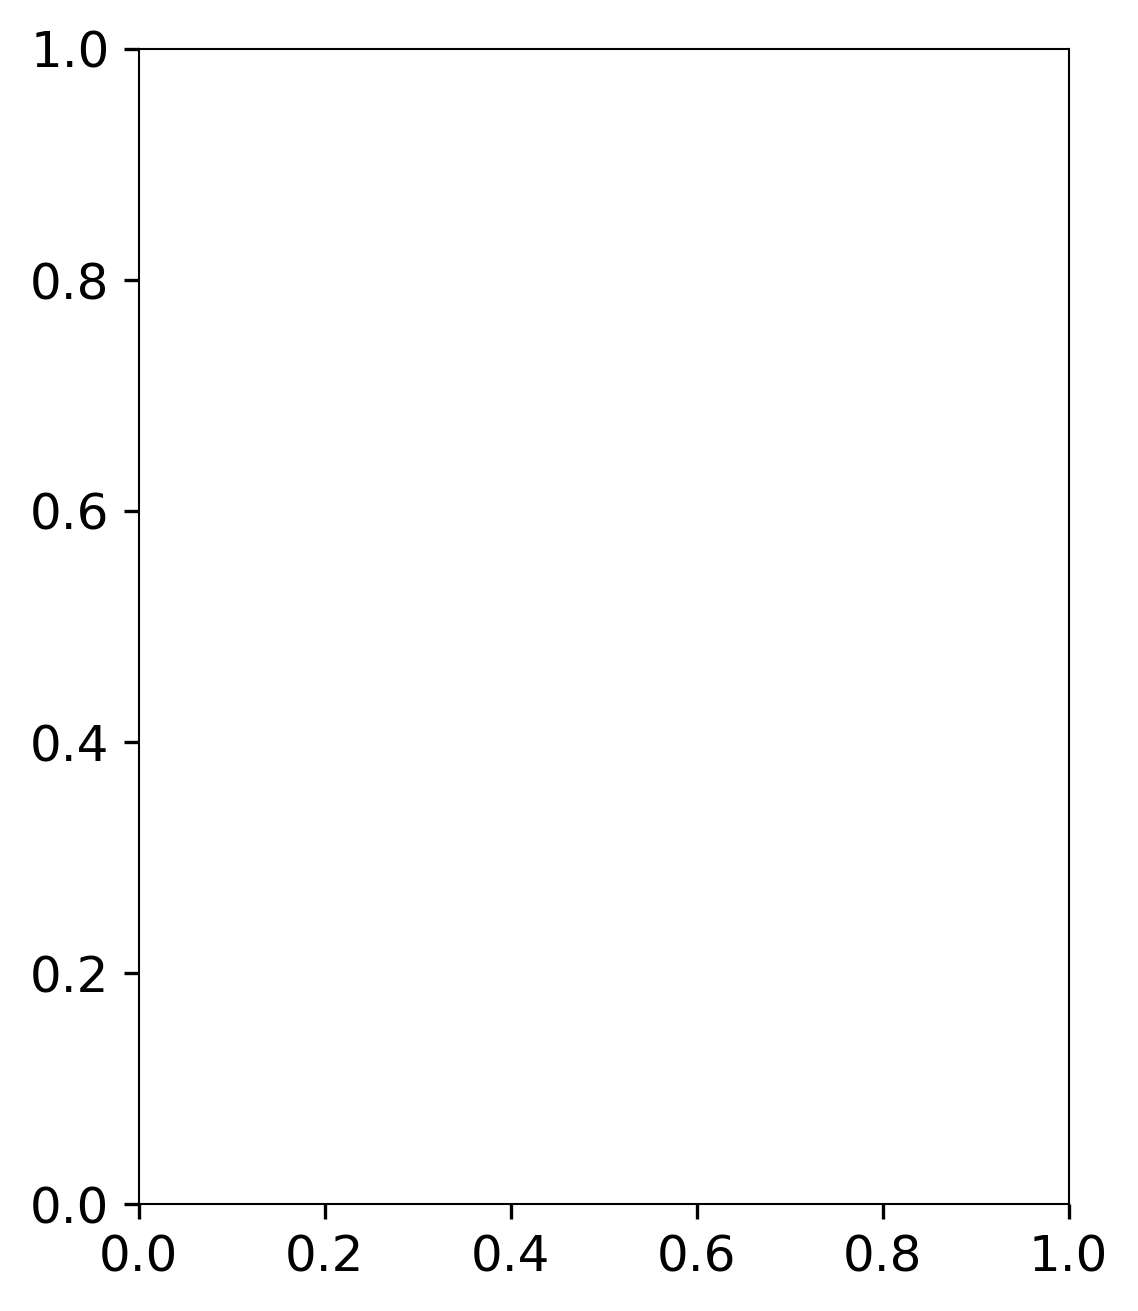

In [ ]:
from matplotlib import pyplot as plt
import numpy as np
import scienceplots
plt.rcParams['figure.dpi'] = 300
plt.style.use(['nature']) # start with ['science'] then ['nature']. use 'notebook', 'no-latex', 'cjk-jp-font' if needed.
plt.rc('axes', titlesize=15, labelsize=15)      # Title font size
plt.rc('xtick', labelsize=12)     # X-axis tick font size
plt.rc('ytick', labelsize=12)     # Y-axis tick font size
plt.rc('legend', fontsize=13)     # Legend font sizplt

print(plt.rcParams['axes.prop_cycle'].by_key()['color'])

Mann-Whitney U検定: U=421517052.00, p-value=0.0000


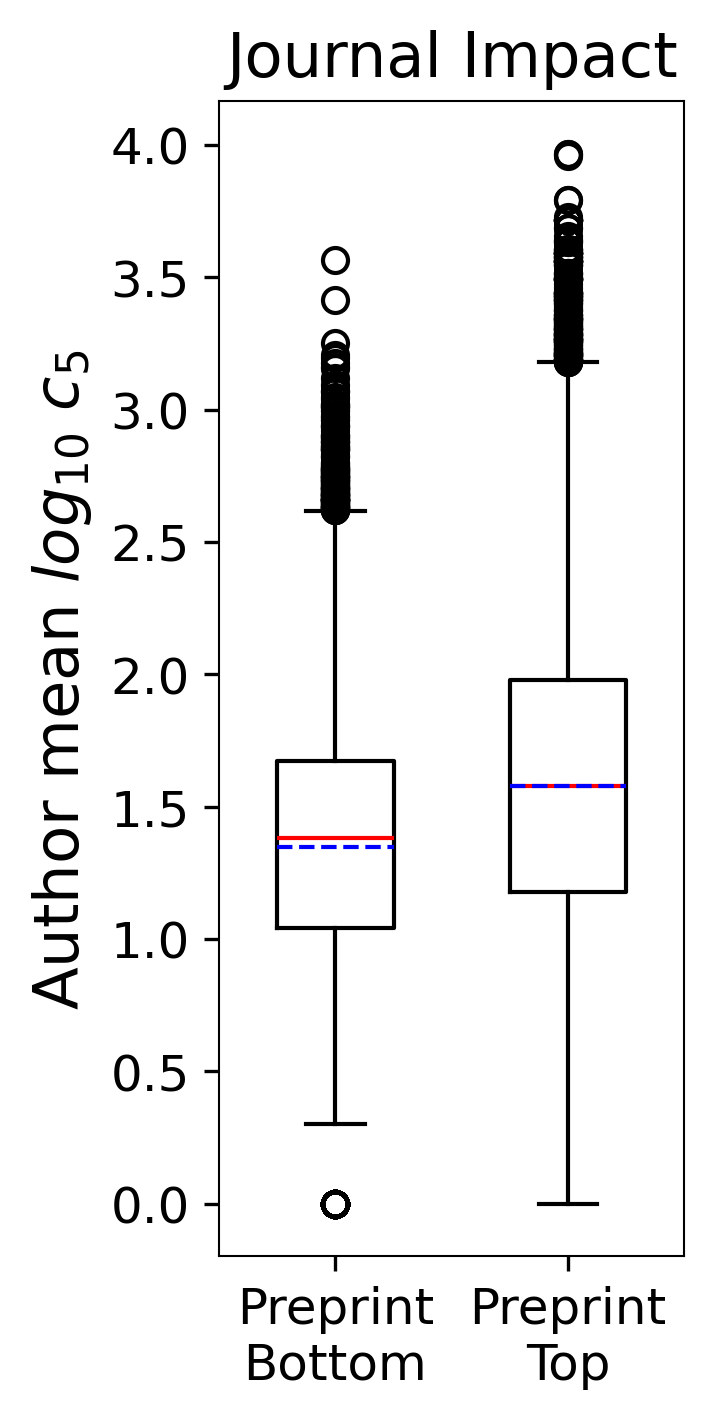

In [55]:
import pandas as pd
import numpy as np
# import seaborn as sns
import pandas as pd
from scipy.stats import mannwhitneyu

def c5_is_significant(cols, labels, ax):
    # 対数変換（log1pを使って0も扱えるように）
    log_counts_all = np.log10(cols[0] +1)
    log_counts_unique = np.log10(cols[1] +1)
    
    # # データをまとめてプロット用に整形
    # df_plot = pd.DataFrame({
    #     colname[0]: log_counts_all,
    #     colname[1]: log_counts_unique
    # })
    
    # 箱ひげ図の描画
    
    ax.boxplot(
        [log_counts_all, log_counts_unique],
        widths=0.5,
        labels=("Preprint\nBottom", "Preprint\nTop"),
        showmeans=True,
        meanline=True,
        boxprops=dict(color='black'),
        medianprops=dict(color='red'),
        meanprops=dict(color='blue')
    )
    # df_plot.boxplot(ax=ax)
    # sns.violinplot(data=df_plot)
    ax.set_ylabel(labels['ylabel'])
    ax.set_title(labels['title'])
    
    # Mann-Whitney U検定
    stat, p = mannwhitneyu(log_counts_all, log_counts_unique, alternative='two-sided')
    
    return stat, p 
    
fig, ax = plt.subplots(1,1, figsize=(2,5))

stat, p = c5_is_significant(
    (scopus_work[scopus_work['tier']=='middle']['c5'].dropna(),
    scopus_work[scopus_work['tier']=='top']['c5'].dropna()),
    labels={'ylabel':'Author mean $log_{10}$ $c_{5}$', 'title':'Journal Impact'},
    ax=ax
)
print(f"Mann-Whitney U検定: U={stat:.2f}, p-value={p:.4f}")

In [67]:
unique_values = np.unique(group1)
print(unique_values)


[0.         0.30103    0.47712125 0.60205999 0.69897    0.77815125
 0.84509804 0.90308999 0.95424251 1.         1.04139269 1.07918125
 1.11394335 1.14612804 1.17609126 1.20411998 1.23044892 1.25527251
 1.2787536  1.30103    1.32221929 1.34242268 1.36172784 1.38021124
 1.39794001 1.41497335 1.43136376 1.44715803 1.462398   1.47712125
 1.49136169 1.50514998 1.51851394 1.53147892 1.54406804 1.5563025
 1.56820172 1.5797836  1.59106461 1.60205999 1.61278386 1.62324929
 1.63346846 1.64345268 1.65321251 1.66275783 1.67209786 1.68124124
 1.69019608 1.69897    1.70757018 1.71600334 1.72427587 1.73239376
 1.74036269 1.74818803 1.75587486 1.76342799 1.77085201 1.77815125
 1.78532984 1.79239169 1.79934055 1.80617997 1.81291336 1.81954394
 1.8260748  1.83250891 1.83884909 1.84509804 1.85125835 1.8573325
 1.86332286 1.86923172 1.87506126 1.88081359 1.88649073 1.8920946
 1.89762709 1.90308999 1.90848502 1.91381385 1.91907809 1.92427929
 1.92941893 1.93449845 1.93951925 1.94448267 1.94939001 1.9542425

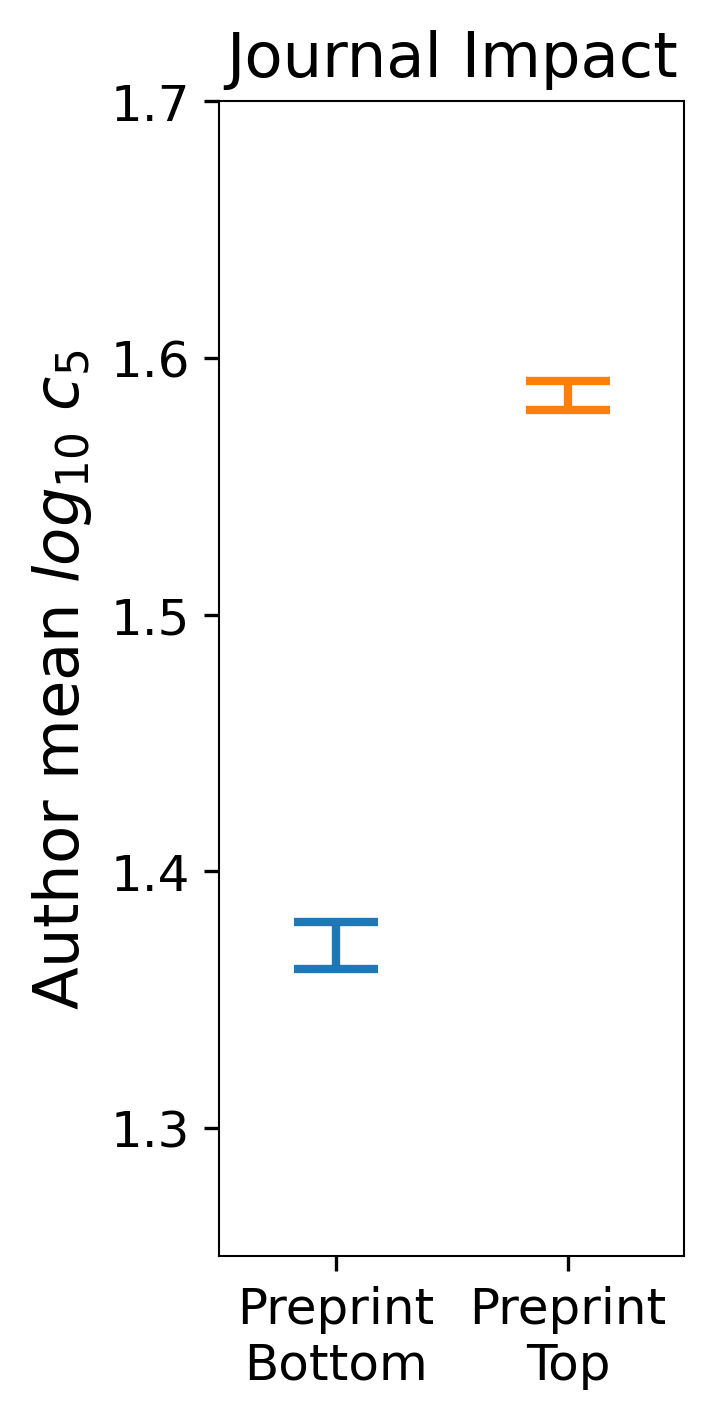

In [125]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, bootstrap

def median_func(data, axis=0):
    return np.median(data, axis=axis)

def bootstrapped_interval(data):
    res = bootstrap(
        (data,),
        median_func,
        confidence_level=0.95,
        n_resamples=1000,
        method='percentile'
    )
    median_val = np.median(data)
    ci_low = res.confidence_interval.low
    ci_high = res.confidence_interval.high
    
    return median_val - ci_low, ci_high - median_val

def draw_errorbar(medians, err):
    for i, e in enumerate(err):
        ax.errorbar(
            x = [i],
            y = [medians[i]],
            yerr=np.array([[e[0]], [e[1]]]),  # two-sided error bars
            fmt='none',  # 'o' for circular markers
            color=plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
            linewidth=2,
            capsize=10,
            capthick=2,
        )
def confidence_interval(cols, labels, ax):
    # 対数変換（log1pを使って0も扱えるように）
    log_counts_all = np.log10(cols[0] +1)
    log_counts_unique = np.log10(cols[1] +1)
    
    # # データをまとめてプロット用に整形
    # df_plot = pd.DataFrame({
    #     colname[0]: log_counts_all,
    #     colname[1]: log_counts_unique
    # })
    
    # 箱ひげ図の描画
    err = [bootstrapped_interval(log_counts_all), bootstrapped_interval(log_counts_unique)]
    draw_errorbar([np.median(log_counts_all), np.median(log_counts_unique)], err)
    ax.set_xticks([0, 1], ['Preprint\nBottom', 'Preprint\nTop'])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylabel(labels['ylabel'])
    ax.set_title(labels['title'])
    # ax.boxplot(
    #     [log_counts_all, log_counts_unique],
    #     widths=0.5,
    #     labels=("Preprint\nBottom", "Preprint\nTop"),
    #     showmeans=True,
    #     meanline=True,
    #     boxprops=dict(color='black'),
    #     medianprops=dict(color='red'),
    #     meanprops=dict(color='blue')
    # )
    # sns.violinplot(data=df_plot)
    
    
    # Mann-Whitney U検定
    stat, p = mannwhitneyu(log_counts_all, log_counts_unique, alternative='two-sided')
    
    return stat, p 

fig, ax = plt.subplots(1,1, figsize=(2,5))
confidence_interval(
    (scopus_work[scopus_work['tier']=='middle']['c5'].dropna(),
    scopus_work[scopus_work['tier']=='top']['c5'].dropna()),
    labels={'ylabel':'Author mean $log_{10}$ $c_{5}$', 'title':'Journal Impact'},
    ax=ax
)
ax.set_ylim(1.25, 1.7)
ax.set_yticks([1.3, 1.4, 1.5, 1.6, 1.7])

(1.8, 2.25)

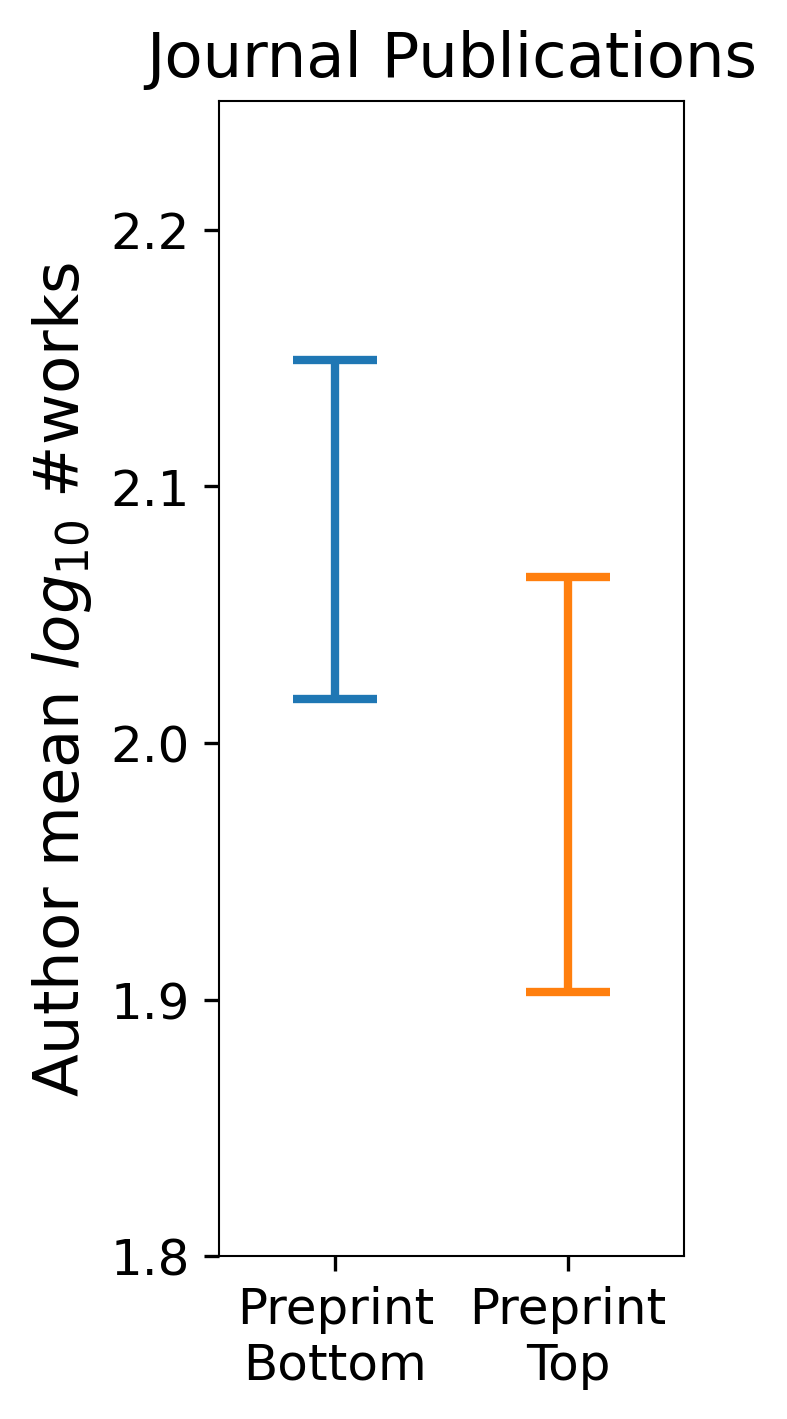

In [124]:
fig, ax = plt.subplots(1,1, figsize=(2,5))
confidence_interval(
    (
        scopus_work[scopus_work['tier']=='middle'].dropna(subset='c5').groupby('authids')['eid'].size(),
        scopus_work[scopus_work['tier']=='top'].dropna(subset='c5').groupby('authids')['eid'].size()
    ),
    labels={'ylabel':'Author mean $log_{10}$ #works', 'title':'Journal Publications'},
    ax=ax
)

ax.set_yticks([1.8, 1.9, 2.0, 2.1, 2.2])
ax.set_ylim(1.8, 2.25)

In [251]:
scopus_work[scopus_work['tier']=='middle'].groupby('authids')['eid'].size()

authids
6.506727e+09    191
6.506832e+09    239
6.506935e+09    144
6.507065e+09    107
6.507225e+09     84
               ... 
5.720494e+10     77
5.720604e+10    172
5.720751e+10    220
5.722302e+10    243
5.803255e+10    450
Name: eid, Length: 213, dtype: int64

In [42]:
scopus_work[scopus_work['tier']=='middle'].dropna(subset='c5').groupby('authids')['eid'].size()

authids
6.506727e+09    113
6.506832e+09    107
6.506935e+09     89
6.507065e+09     67
6.507225e+09     49
               ... 
5.720494e+10     21
5.720604e+10     67
5.720751e+10    144
5.722302e+10    171
5.803255e+10    178
Name: eid, Length: 213, dtype: int64

Mann-Whitney U検定: U=24094.00, p-value=0.3070


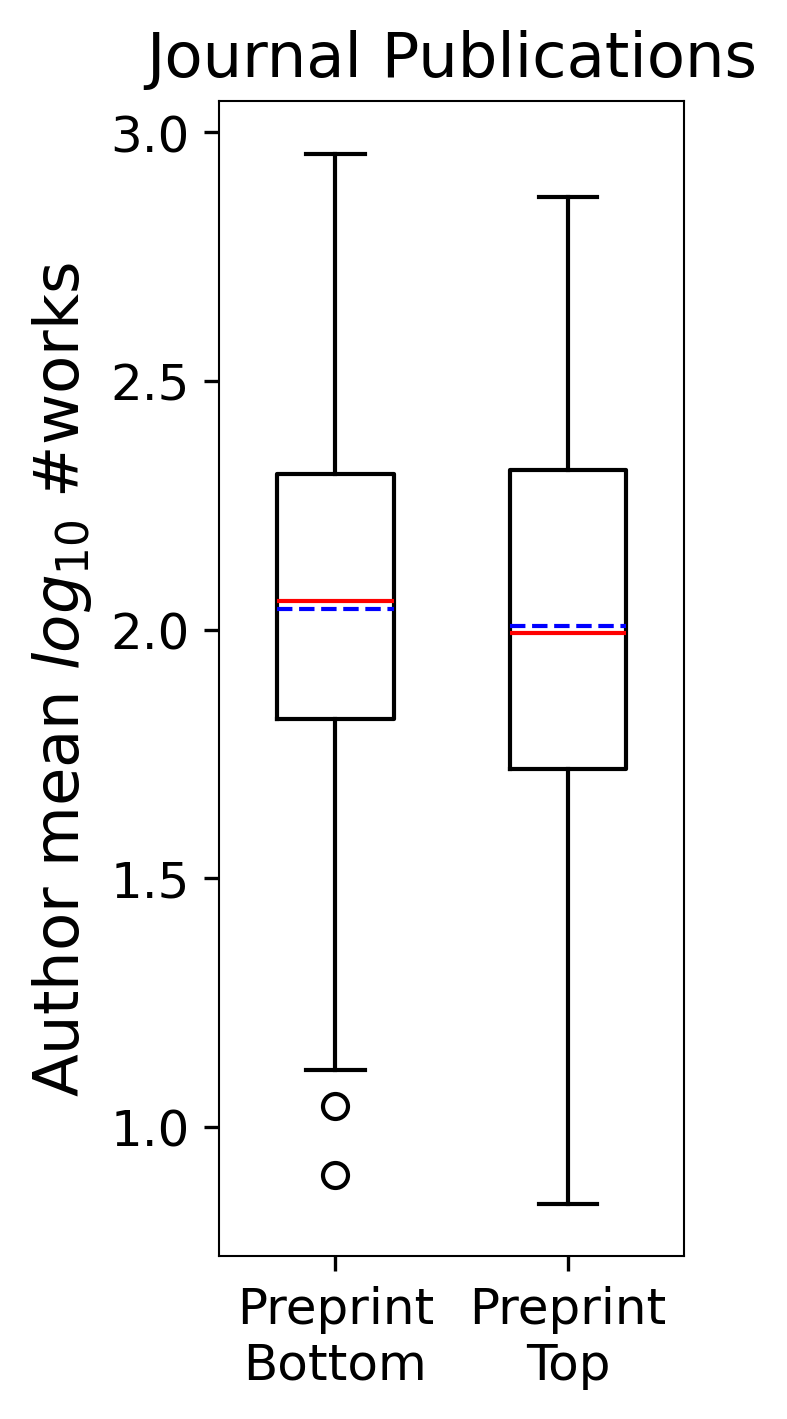

In [56]:
# 生産性の違い
fig, ax = plt.subplots(1,1, figsize=(2,5))

stat, p = c5_is_significant(
    (
        scopus_work[scopus_work['tier']=='middle'].dropna(subset='c5').groupby('authids')['eid'].size(),
        scopus_work[scopus_work['tier']=='top'].dropna(subset='c5').groupby('authids')['eid'].size()
    ),
    labels={'ylabel':'Author mean $log_{10}$ #works', 'title':'Journal Publications'},
    ax=ax
)

print(f"Mann-Whitney U検定: U={stat:.2f}, p-value={p:.4f}")